# Notebook for Processing CMAQ Annual Chemical Budget to Assess Potential Mass Closure Issues

- Author: Ben Murphy
- Date: 2021-10-27
- Sim Details: 2018 Case; CB6r5_AE7_AQ; M3DRY
- Data Location: /shared/build/openmpi_gcc/CMAQ_v54+/data/output_CCTM_v54_gcc_12US1_LISTOS

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
from datetime import datetime
from datetime import timedelta
from dateutil import rrule
from matplotlib.patches import Patch

### Load All Data

In [2]:
# Three-Day Dataset
filepath = '/shared/build/openmpi_gcc/CMAQ_v54+/data/output_CCTM_v54_gcc_12US1_LISTOS/'
filename = 'CCTM_BUDGET_v54_gcc_12US1_LISTOS_'
date0 = datetime.strptime("20180805","%Y%m%d")
ndays = 3
filepath

# Annual Dataset (uncomment the next 4 lines)
#filepath = '/home/bmurphy/projdir/ROC/Budget/2016_CONUS/budget_files/'
#filename = 'CCTM_BUDGET_v532_intel18.0_2016_CONUS_'
#date0 = datetime.strptime("20160101","%Y%m%d")
#ndays = 366

'/shared/build/openmpi_gcc/CMAQ_v54+/data/output_CCTM_v54_gcc_12US1_LISTOS/'

In [3]:
# Build array of dates to read in
farray = []
for dt in rrule.rrule(rrule.DAILY, dtstart=date0, until=date0+timedelta(days=ndays)+timedelta(hours=-1)):
    farray.append(dt.strftime('%Y%m%d'))
farray

['20180805', '20180806', '20180807']

In [4]:
bdf = pd.concat([pd.read_csv(f'{filepath+filename}{id}.txt', delimiter=',', comment='#', index_col=['SPECIES', 'T_START',]) for id in farray])
bdf


,,T_FINAL,T_DELTA,M_START,M_FINAL,M_DELTA,WEST_IN,WEST_OUT,EAST_IN,EAST_OUT,SOUTH_IN,...,EMIS,DDEP,PVO3,CLDS,CHEM,COND,COAG,NPF,GROW,RESID
SPECIES,T_START,,,,,,,,,,,,,,,,,,,,,
NO2,2018-08-05T00:00:00Z,2018-08-05T01:00:00Z,1.0,1.718872e+05,2.269882e+05,5.510099e+04,3.615269e+04,-110.680280,5.388153e+01,-1.544069e+04,3.890006e+03,...,2258.3894,-754.928960,0.0,1.582336e-02,1.306953e+04,0.000000,0.0,0.0,0.0,-1.037891e+01
NO,2018-08-05T00:00:00Z,2018-08-05T01:00:00Z,1.0,2.841646e+02,3.845739e+02,1.004093e+02,2.317244e+01,-0.060319,1.504424e-02,-3.818625e+01,9.478527e+00,...,12495.3290,-21.479410,0.0,1.967288e-03,-1.235252e+04,0.000000,0.0,0.0,0.0,3.280640e-03
O,2018-08-05T00:00:00Z,2018-08-05T01:00:00Z,1.0,3.698940e-10,2.457720e-11,-3.453168e-10,0.000000e+00,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,...,0.0000,0.000000,0.0,1.218252e-11,-3.575001e-10,0.000000,0.0,0.0,0.0,5.551115e-17
O3,2018-08-05T00:00:00Z,2018-08-05T01:00:00Z,1.0,1.947416e+08,1.838571e+08,-1.088454e+07,1.128552e+07,-964273.120000,2.124238e+06,-2.394227e+07,2.988101e+06,...,0.0000,-29838.289000,0.0,-6.630628e+01,-5.084995e+04,0.000000,0.0,0.0,0.0,2.688000e+03
NO3,2018-08-05T00:00:00Z,2018-08-05T01:00:00Z,1.0,1.969427e+03,6.211235e+03,4.241809e+03,4.382172e+02,-0.613486,1.383784e+00,-3.922858e+02,8.458880e+01,...,0.0000,-6.175714,0.0,-2.170052e-04,3.894097e+03,0.000000,0.0,0.0,0.0,-8.740234e-02
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
SVMT2,2018-08-07T23:00:00Z,2018-08-08T00:00:00Z,1.0,1.108475e+02,1.096541e+02,-1.193399e+00,6.804984e+00,-0.000359,9.058612e-03,-8.582673e+00,8.561785e+00,...,0.0000,-3.629930,0.0,-4.165632e+00,0.000000e+00,4.026576,0.0,0.0,0.0,-6.537437e-04
SVMT3,2018-08-07T23:00:00Z,2018-08-08T00:00:00Z,1.0,7.069008e+02,6.941393e+02,-1.276144e+01,4.793222e+01,-0.001667,1.689962e-01,-5.088880e+01,3.626584e+01,...,0.0000,-11.130340,0.0,-1.822910e+01,0.000000e+00,12.447380,0.0,0.0,0.0,-1.125336e-03
SVMT4,2018-08-07T23:00:00Z,2018-08-08T00:00:00Z,1.0,4.840048e+03,4.738428e+03,-1.016197e+02,3.637162e+02,-0.008709,3.917674e+00,-2.987928e+02,1.495097e+02,...,0.0000,-33.989655,0.0,-8.538007e+01,0.000000e+00,28.032831,0.0,0.0,0.0,3.669739e-03


In [5]:
A = [ bdf.index[im][0] for im in range(bdf.shape[0]) ]
species = np.unique(np.array(A))
bdf.columns

Index(['T_FINAL', 'T_DELTA', 'M_START', 'M_FINAL', 'M_DELTA', 'WEST_IN',
       'WEST_OUT', 'EAST_IN', 'EAST_OUT', 'SOUTH_IN', 'SOUTH_OUT', 'NORTH_IN',
       'NORTH_OUT', 'ZADV', 'HDIF', 'VDIF', 'EMIS', 'DDEP', 'PVO3', 'CLDS',
       'CHEM', 'COND', 'COAG', 'NPF', 'GROW', 'RESID'],
      dtype='object')

## Aggregate Budget Rates into Broader Process Categories

In [6]:
def get_spc_bdf(dfp, spck):
    
    if spck == 'EC':
        spc_bdf = dfp.xs('AECI') + dfp.xs('AECJ')
    else:
        spc_bdf = dfp.xs(spck).copy()

    spc_bdf.eval('TADV = NORTH_IN + NORTH_OUT + SOUTH_IN + SOUTH_OUT + WEST_IN + WEST_OUT + EAST_IN + EAST_OUT + ZADV', inplace=True)
    spc_bdf.eval('XADV = WEST_IN + WEST_OUT + EAST_IN + EAST_OUT', inplace=True)
    spc_bdf.eval('YADV = NORTH_IN + NORTH_OUT + SOUTH_IN + SOUTH_OUT', inplace=True)
    spc_bdf.eval(f'AERO = COND + COAG + NPF + GROW', inplace=True)
    spc_bdf.eval('DIF = HDIF + VDIF', inplace=True)
    spc_bdf.eval('SUMP = TADV + EMIS + DDEP + CLDS + CHEM + AERO + PVO3', inplace=True)
    return spc_bdf

## Classify data into Time of Day

In [7]:
# First define full time vector
dtarray = []
for dt in rrule.rrule(rrule.HOURLY, dtstart=date0, until=date0+timedelta(days=ndays)):
    dtarray.append(dt)
    
# Now Create Day and Night Masks
night = np.array([ dtarray[i].hour >= 2 and dtarray[i].hour <  14 for i in range( len( dtarray)-1) ])
day   = np.array([ not(night[i]) for i in range( len( dtarray)-1) ])

## Make a Basic Bar Plot of the Production and Loss of EC
Plot the y-axis in log space with negative numbers possible.

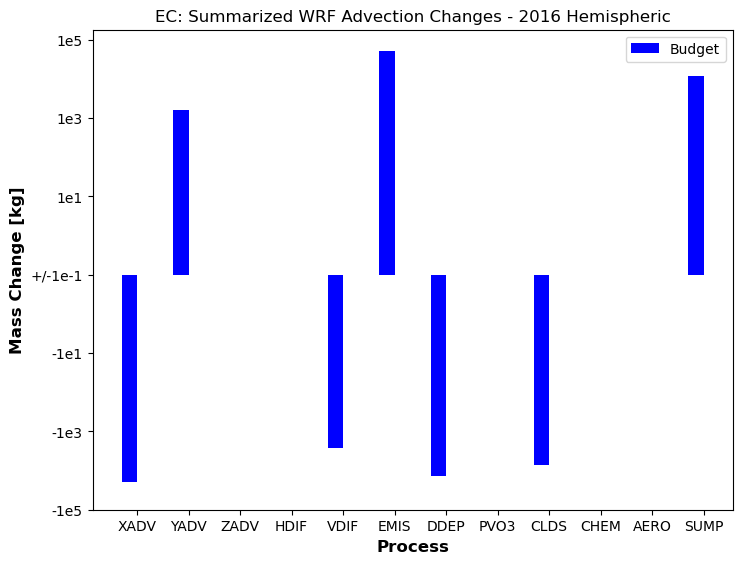

,process,Budget
0,XADV,-19248.999572
1,YADV,1596.868131
2,ZADV,0.000650
3,HDIF,-0.000080
4,VDIF,-2585.845028
5,EMIS,50893.385507
6,DDEP,-14093.394340
7,PVO3,0.000000
8,CLDS,-7277.909696
9,CHEM,0.000000


In [8]:
# Output Species
spck = 'EC'

#Processes for Output
outkeys  = ['XADV', 'YADV', 'ZADV', 'HDIF',  'VDIF', 'EMIS', 'DDEP', 'PVO3', \
            'CLDS', 'CHEM', 'COND', 'COAG', 'NPF', 'GROW','SUMP','AER']

# Plotting Parameters
ysmin = 1e-1  # Minimum of the positive and negative sides of the y axis (i.e. cross-over point)
tickstep = 2  # Orders of magnitude between ticks on the y axis
              # The y-axis maximum can be controlled by 'ylarge' below.

for si, spck in enumerate([spck]):
    ti = si + 1
    spc_bdf = get_spc_bdf(bdf, spck)

x = ['XADV', 'YADV', 'ZADV', 'HDIF','VDIF', 'EMIS', 'DDEP', 'PVO3', 'CLDS', 'CHEM', 'AERO','SUMP']
z2 = spc_bdf.loc[:, x].sum().to_numpy()

# Create Log Axis
A2 = np.copy(z2)
logmin = np.log10(ysmin)
A2[ z2 > 0 ] = np.log10(A2[ z2 > 0].clip(ysmin)) - logmin
A2[ z2 < 0 ] = -1 * (np.log10(abs(A2 [ z2 < 0 ]).clip(ysmin)) - logmin)

# Make new tick marks
A = A2 #np.concatenate((A1,A2))
z = z2 #np.concatenate((z1,z2))
tick_mks = list(range(-int(np.ceil(abs(A).max())),0,tickstep)) + [0] + list(range(tickstep, int(np.ceil(abs(A).max()))+1,tickstep ))
ylarge = int(np.ceil(np.log10(np.max(abs(z)))))
yfuzzy = int(logmin)
tick_labs_exp = list(range(ylarge,yfuzzy-1,-tickstep)) + list(range(yfuzzy+tickstep,ylarge+1,tickstep))
neglen = len(list(range(ylarge,yfuzzy-1,-tickstep)))-1
tick_labs = ['1e'+str(x) for x in tick_labs_exp]
tick_labs[ 0:neglen ] = ['-'+x for x in tick_labs[0:neglen]]
tick_labs[ neglen ] = '+/-'+ tick_labs[neglen]

# Plot Data
fig = plt.figure()
bar_width = 0.3
X = np.arange(len(A2))
ax = fig.add_axes([0,0,1,1])
ax.bar(X, A2, bar_width, color='b',label='Budget')
#ax.bar(X,A1, bar_width, color='k',label='Process Analysis')
#ax.bar(X+bar_width, A2, bar_width, color='b',label='Budget')
ax.set_xticks(X + bar_width/2)
ax.set_xticklabels(x)
ax.set_xlabel('Process',fontweight='bold',fontsize='large')
ax.set_ylabel('Mass Change [kg]',fontweight='bold',fontsize='large')
ax.set_yticks(tick_mks)
ax.set_yticklabels(tick_labs)
ax.set_title(spck + ': Summarized WRF Advection Changes - 2016 Hemispheric')
ax.legend()
plt.show()

pd.DataFrame(data={'process':x, 'Budget':z2})

## Make a more Complex Plot with Day/Night Classification

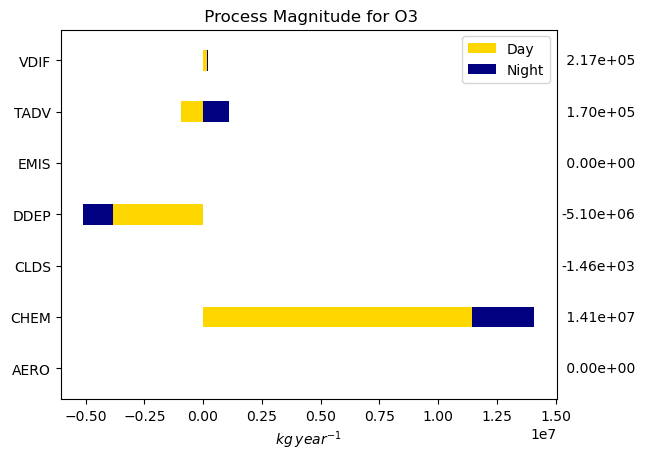

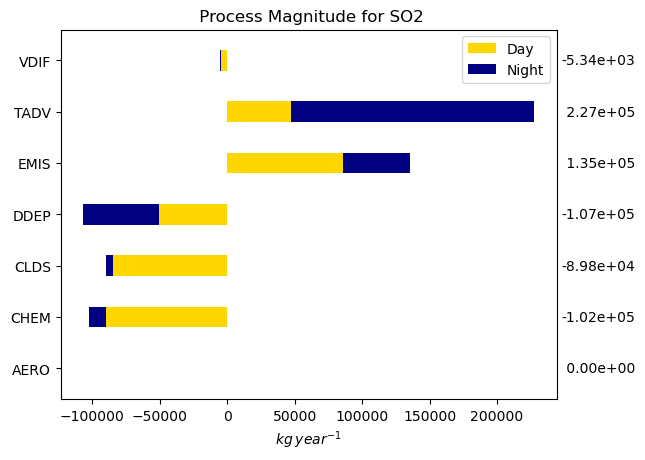

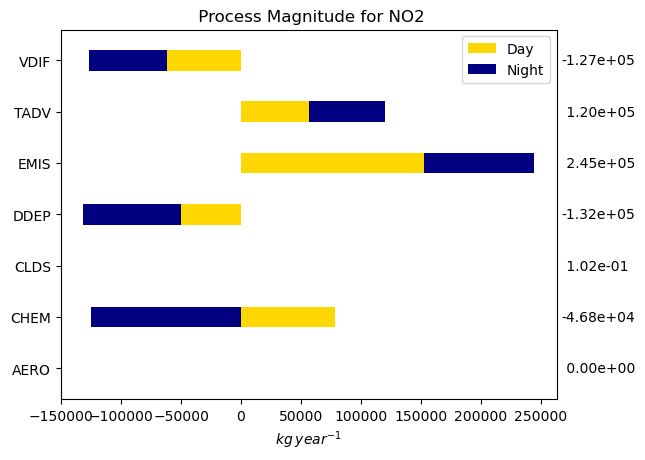

In [9]:
outkeys  = ['VDIF', 'TADV', 'EMIS', 'DDEP', 'CLDS', 'CHEM', 'AERO']
frmt = "{:11}"*len(outkeys)
outkeysr = outkeys[::-1]
season_time = ['DayWin','NightWin','DaySpr','NightSpr','DaySum','NightSum','DayAut','NightAut']
spec = ['O3','SO2','NO2']
legend_elements = [Patch(facecolor='gold', label='Day'),
                   Patch(facecolor='navy', label='Night')]

for si, spck in enumerate(spec):
    ti = si + 1
    spc_bdf = get_spc_bdf(bdf, spck)
    
    annual_day1 = spc_bdf.loc[day, outkeys].sum()[::-1]
    annual_ngt1 = spc_bdf.loc[night, outkeys].sum()[::-1]

    ind = np.arange(len(outkeys))
    width = 0.4
    
    f1, sax = plt.subplots(1,1)
    
    for i in range(len(outkeys)):
        p1 = plt.barh( ind[i]+width, annual_day1[i], width, color='gold' )
        if annual_day1[i] * annual_ngt1[i] >= 0:
            p2 = plt.barh( ind[i]+width, annual_ngt1[i], width, left = annual_day1[i],color='navy',label='Night' )
        else:
            p2 = plt.barh( ind[i]+width, annual_ngt1[i], width, left = 0,color='navy',label='Night' )

    ax = plt.gca()
    ax.set(yticks=ind + width, yticklabels=outkeysr, ylim=[2*width - 1, len(outkeysr)],xlabel='$kg \: year^{-1}$')
    ax.legend(handles=legend_elements)
    plt.title( ' Process Magnitude for ' + spck)

    # Add total and maximum season-time-of-day
    x = ax.get_xlim()
    annual = annual_day1 + annual_ngt1
    [ ax.text(x[1]+(x[1]-x[0])/100,ind[im]+width-width/5,'%9.2e' % annual[im]) for im in np.arange(len(outkeys))]

    plt.savefig('/shared/build/openmpi_gcc/CMAQ_v54+/data/budget_tool_figs/Fig1_' + spck + '.png', bbox_inches='tight')

## Add Seasonal Classification
(only available if Annual Data Are Provided)

### Set Up Seasonal Masks

In [10]:
# Now create season masks
winter = np.array([ dtarray[i].month == 1 or dtarray[i].month ==  2 or dtarray[i].month == 12 for i in range( len( dtarray)-1) ])
spring = np.array([ dtarray[i].month == 3 or dtarray[i].month ==  4 or dtarray[i].month ==  5 for i in range( len( dtarray)-1) ])
summer = np.array([ dtarray[i].month == 6 or dtarray[i].month ==  7 or dtarray[i].month ==  8 for i in range( len( dtarray)-1) ])
autumn = np.array([ dtarray[i].month == 9 or dtarray[i].month == 10 or dtarray[i].month == 11 for i in range( len( dtarray)-1) ])

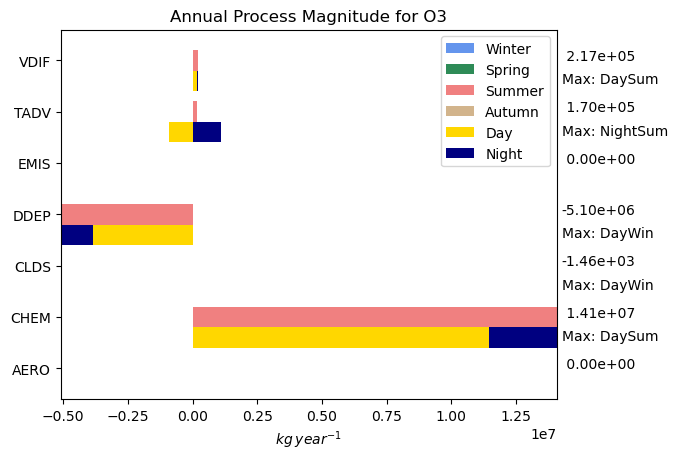

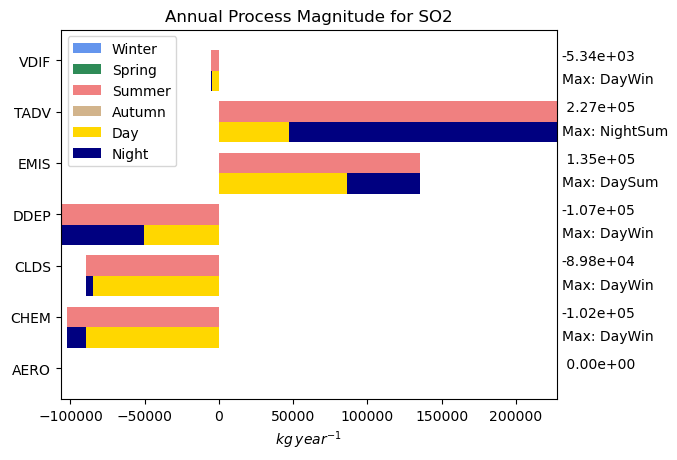

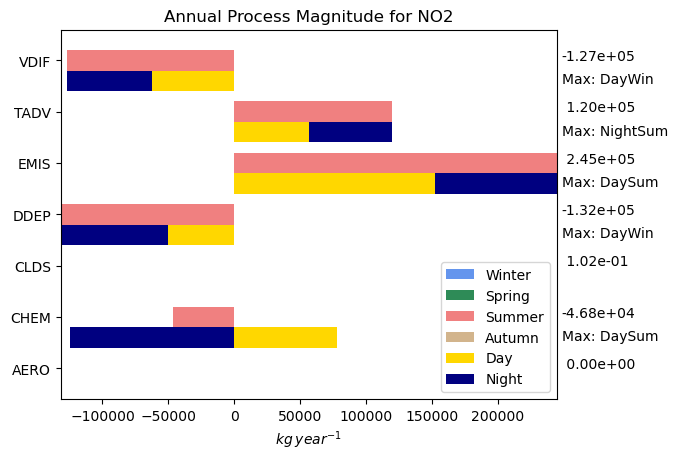

In [11]:
outkeys  = ['VDIF', 'TADV', 'EMIS', 'DDEP', 'CLDS', 'CHEM', 'AERO']
frmt = "{:11}"*len(outkeys)
outkeysr = outkeys[::-1]
season_time = ['DayWin','NightWin','DaySpr','NightSpr','DaySum','NightSum','DayAut','NightAut']
spec = ['O3','SO2','NO2']
legend_elements = [Patch(facecolor='cornflowerblue', label='Winter'),
                   Patch(facecolor='seagreen', label='Spring'),
                   Patch(facecolor='lightcoral', label='Summer'),
                   Patch(facecolor='tan', label='Autumn'),
                   Patch(facecolor='gold', label='Day'),
                   Patch(facecolor='navy', label='Night')]

for si, spck in enumerate(spec):
    ti = si + 1
    spc_bdf = get_spc_bdf(bdf,spck)
    
    winter_day = spc_bdf.loc[winter & day, outkeys].sum()[::-1]
    winter_ngt = spc_bdf.loc[winter & night, outkeys].sum()[::-1]
    winter_all = winter_day + winter_ngt
    spring_day = spc_bdf.loc[spring & day, outkeys].sum()[::-1]
    spring_ngt = spc_bdf.loc[spring & night, outkeys].sum()[::-1]
    spring_all = spring_day + spring_ngt
    summer_day = spc_bdf.loc[summer & day, outkeys].sum()[::-1]
    summer_ngt = spc_bdf.loc[summer & night, outkeys].sum()[::-1]
    summer_all = summer_day + summer_ngt
    autumn_day = spc_bdf.loc[autumn & day, outkeys].sum()[::-1]
    autumn_ngt = spc_bdf.loc[autumn & night, outkeys].sum()[::-1]
    autumn_all = autumn_day + autumn_ngt
    
    annual_day = spc_bdf.loc[day, outkeys].sum()[::-1]
    annual_ngt = spc_bdf.loc[night, outkeys].sum()[::-1]
    
    ind = np.arange(len(outkeys))
    width = 0.4
    
    f1, sax = plt.subplots(1,1)
    
    p1 = plt.barh( ind+width, winter_all, width, color='cornflowerblue',label='Winter' )
    p2 = plt.barh( ind+width, spring_all, width, left = winter_all, color='seagreen',label='Spring' )
    p3 = plt.barh( ind+width, summer_all, width, left = winter_all+spring_all, color='lightcoral',label='Summer' )
    p4 = plt.barh( ind+width, autumn_all, width, left = winter_all+spring_all+summer_all, color='tan',label='Autumn' )
    
    for i in range(len(outkeys)):
        p5 = plt.barh( ind[i], annual_day[i], width, color='gold', label='Day' )
        if annual_day[i] * annual_ngt[i] >= 0:
            p6 = plt.barh( ind[i], annual_ngt[i], width, left = annual_day[i],color='navy',label='Night' )
        else:
            p6 = plt.barh( ind[i], annual_ngt[i], width, left = 0,color='navy',label='Night' )
            
    ax = plt.gca()
    ax.set(yticks=ind + width, yticklabels=outkeysr, ylim=[2*width - 1, len(outkeysr)],xlabel='$kg \: year^{-1}$')
    ax.legend(handles=legend_elements)
    plt.title('Annual Process Magnitude for '+ spck)
    
    # Add total and maximum season-time-of-day
    x = ax.get_xlim()
    annual = annual_day + annual_ngt
    [ ax.text(x[1]+(x[1]-x[0])/100,ind[im]+width,'%9.2e' % annual[im]) for im in np.arange(len(outkeys))]
    for im in range(len(outkeys)):
        A = [winter_day[im], winter_ngt[im], spring_day[im], spring_ngt[im], summer_day[im], summer_ngt[im], autumn_day[im], autumn_ngt[im]]
        if abs(annual[im]) > 1.0:
            ax.text(x[1]+(x[1]-x[0])/100,ind[im]-0.05, 'Max: ' + season_time[A.index(max(A))] )
        
    plt.savefig('/shared/build/openmpi_gcc/CMAQ_v54+/data/2016_CONUS/budget_tool_figs/Fig1_' + spck + '.png', bbox_inches='tight')

## Make Tables of Seasonal and Day/Night Classifications

In [20]:
outkeys  = ['VDIF', 'ADV', 'EMIS', 'DDEP', 'CLDS', 'CHEM', 'AER', 'SUMP']
frmt = "{:11}"*len(outkeys)

#for si, spck in enumerate(['HNO3','O3', 'EC', 'ASO4J','ASO4K','ANO3J','ANH4J','ASEACAT','ASVPO1J','NUMATKN']):
spec = ['O3','SO2','NO2']
for si, spck in enumerate(spec):
    ti = si + 1
    spc_bdf = get_spc_bdf(spck)

    pd.options.display.float_format = '{:.2e}'.format
    print(f'\nTable {ti}: {spck}\n----------------------------')
    print('Process:       ', frmt.format(*outkeys))
    print('Winter(Day):  ', *['%9.2e ' % id for id in spc_bdf.loc[winter & day, outkeys].sum()[:]] )
    print('Winter(Night):', *['%9.2e ' % id for id in spc_bdf.loc[winter & night, outkeys].sum()[:]] )
    print('Winter(Total):', *['%9.2e ' % id for id in spc_bdf.loc[winter, outkeys].sum()[:]] )
    
    print('Spring(Day):  ', *['%9.2e ' % id for id in spc_bdf.loc[spring & day, outkeys].sum()[:]] )
    print('Spring(Night):', *['%9.2e ' % id for id in spc_bdf.loc[spring & night, outkeys].sum()[:]] )
    print('Spring(Total):', *['%9.2e ' % id for id in spc_bdf.loc[spring, outkeys].sum()[:]] )
    
    print('Summer(Day):  ', *['%9.2e ' % id for id in spc_bdf.loc[summer & day, outkeys].sum()[:]] )
    print('Summer(Night):', *['%9.2e ' % id for id in spc_bdf.loc[summer & night, outkeys].sum()[:]] )
    print('Summer(Total):', *['%9.2e ' % id for id in spc_bdf.loc[summer, outkeys].sum()[:]] )
    
    print('Autumn(Day):  ', *['%9.2e ' % id for id in spc_bdf.loc[autumn & day, outkeys].sum()[:]] )
    print('Autumn(Night):', *['%9.2e ' % id for id in spc_bdf.loc[autumn & night, outkeys].sum()[:]] )
    print('Autumn(Total):', *['%9.2e ' % id for id in spc_bdf.loc[autumn, outkeys].sum()[:]] )
    
    print('Total(Day):   ', *['%9.2e ' % id for id in spc_bdf.loc[day, outkeys].sum()[:]])
    print('Total(Night): ', *['%9.2e ' % id for id in spc_bdf.loc[night, outkeys].sum()[:]])
    print('Total:        ', *['%9.2e ' % id for id in spc_bdf.loc[:, outkeys].sum()[:]])
    print('----------------------------\n* ADV=advection; DIF=HDIF+VDIF; AER=COND+COAG+NPF+GROW; SUMP=ALL including PVO3')

TypeError: get_spc_bdf() missing 1 required positional argument: 'spck'